## Progetto 3 - MovieLens: predizione dei rating e clustering degli utenti
### Obiettivo del progetto

Il progetto deve affrontare due task di Machine Learning:
- task supervisionato: dato un utente e un film predire il rating numerico assegnato compreso tra 0.5 e 5
- task non supervisionato: raggruppare gli utenti in base alle preferenze relative al genere di film

Per la regressione vengono utilizzate MAE e RMSE, mentre il clustering viene valutato attraverso inerzia, Silhouette Score, interpretabilità e stabilità dei gruppi.

Alla fine bisogna verificare se l'informazione di cluster da un vantaggio predittivo rispetto alle normali caratteristiche di utenti e film oppure se il suo contributo è principalmente interpretativo


## Setup e funzioni di supporto

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import adjusted_rand_score, mean_absolute_error, mean_squared_error, silhouette_score

from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler



#calcola la radice dell'errore quadratico medio
def evaluate(y_true, preds):
    mae = mean_absolute_error(y_true, preds)
    rmse = np.sqrt(mean_squared_error(y_true, preds))
    return mae, rmse




## Configurazione 
I principali parametri utilizzati per percorsi dei dati, riproducibilità, split, feature e modelli sono raccolti in questa sezione in modo da poterli modificare da un unico punto

In [2]:
#percorsi
RATINGS_PATH = "data/ratings.csv"
MOVIES_PATH = "data/movies.csv"
LINKS_PATH = "data/links.csv"
TAGS_PATH = "data/tags.csv"

#riproducibilità e dominio del target
RANDOM_STATE = 123
RATING_MIN = 0.5
RATING_MAX = 5.0

#split temporale per utente
HISTORY_PERCENT = 0.60
TRAIN_PERCENT = 0.20
VALIDATION_PERCENT = 0.10
TEST_PERCENT = 0.10

#feature aggregate e clustering
MOVIE_MEAN_WEIGHTED_RATINGS=10.0
GENRE_PREFERENCES_WEIGHTED_RATINGS = 5.0

#K-Means
K_MIN = 2
K_MAX = 7
KMEANS_N_INIT = 10
CLUSTER_STABILITY_RUNS = 20

#PCA
PCA_COMPONENTS = 2

#RANDOM FOREST 
RF_TREES = 200
RF_N_JOBS = -1

#MLP
MLP_HIDDEN_LAYERS = (64,32)
MLP_ACTIVATION = "relu"
MLP_SOLVER = "adam"
MLP_MAX_ITER = 500
MLP_EARLY_STOPPING = True

## Caricamento ed esplorazione dei dati

In [3]:
ratings = pd.read_csv(RATINGS_PATH)
movies = pd.read_csv(MOVIES_PATH)
tags = pd.read_csv(TAGS_PATH)
links = pd.read_csv(LINKS_PATH)

print("ratings:", ratings.shape)
print("movies:", movies.shape)
print("tags:", tags.shape)
print("links:", links.shape)

print("\nValori mancanti nei rating:")
display(ratings.isna().sum())

print("\nDescrizione dei rating:")
display(ratings["rating"].describe())

ratings: (100836, 4)
movies: (9742, 3)
tags: (3683, 4)
links: (9742, 3)

Valori mancanti nei rating:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


Descrizione dei rating:


count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

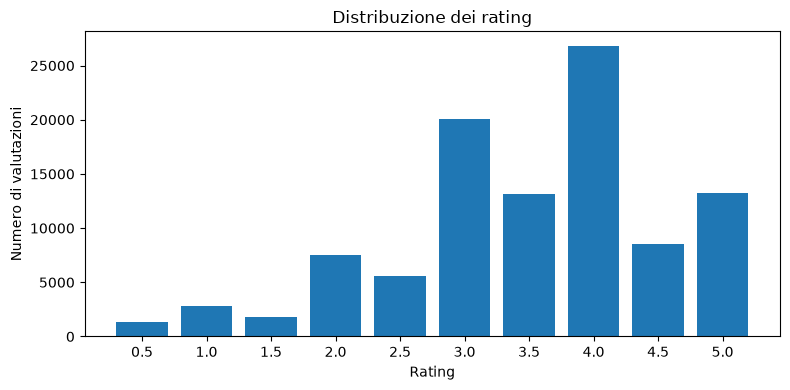

In [4]:
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(8,4))
plt.bar(rating_counts.index.astype(str),rating_counts.values)

plt.title("Distribuzione dei rating")
plt.xlabel("Rating")
plt.ylabel("Numero di valutazioni")
plt.tight_layout()
plt.show()

## Generi e tag
I generi vengono utilizzati come feature del modello utilizzando una codifica multi-hot.

I tag sono annotazioni testuali libere, si analizzano per decidere se usarli o meno

In [5]:
genre_dummies = movies["genres"].str.get_dummies(sep="|")
genre_columns = genre_dummies.columns.tolist()

clustering_genres = [genre for genre in genre_columns if genre != "(no genres listed)"]

print("Numero di generi:", len(genre_columns))
display(genre_dummies.sum().sort_values(ascending=False))

tag_applications = len(tags)
unique_tags = tags["tag"].nunique()
user_with_tags = tags["userId"].nunique()
movies_with_tags = tags["movieId"].nunique()

total_users = ratings["userId"].nunique()
totale_movies = movies["movieId"].nunique()
user_pecentage = (100 * user_with_tags / total_users)
movie_pecentage = (100 * movies_with_tags / totale_movies)


tag_summary = pd.DataFrame({
    "misura": 
            ["applicazioni di tag", "tag distinti", "utenti che utilizzano i tag", 
             "film con almeno un tag" ], 
    "valore":
            [tag_applications, unique_tags, 
             f"{user_pecentage:.2f}%", f"{movie_pecentage:.2f}%"]
            })

display(tag_summary)

Numero di generi: 20


Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
dtype: int64

,misura,valore
0,applicazioni di tag,3683
1,tag distinti,1589
2,utenti che utilizzano i tag,9.51%
3,film con almeno un tag,16.14%


### Scelta relativa ai tag
L'analisi mostra che solo una piccola parte di utenti utilizza i tag; 

la loro rappresentazione essendo testo libero richiederebbe una maggiore complessità a fronte di una copertura ridotta

## Split temporale per utente
Si osserva quanti rating ha un utente per rendere possibile assegnargli almeno un rating in ciascuno dei 4 blocchi. 

In [6]:
ratings = ratings.copy()
ratings["row_order"] = np.arange(len(ratings))

ratings_for_user = ratings.groupby("userId").size()
display(ratings_for_user.describe().to_frame("rating_per_utente"))

print("Minimo osservato:", ratings_for_user.min())



,rating_per_utente
count,610.000000
mean,165.304918
std,269.480584
min,20.000000
25%,35.000000
50%,70.500000
75%,168.000000
max,2698.000000


Minimo osservato: 20


Da questa osservazione emerge che ogni utente ha valutato almeno 20 film

In [7]:
#Divide i rating di un utente in quattro blocchi cronologici.

def temporal_split_for_user(user_ratings):
    ordered = user_ratings.sort_values(["timestamp", "row_order"], kind="stable")
    n = len(ordered)

    n_history = int(n * HISTORY_PERCENT)
    n_train = int(n * TRAIN_PERCENT)
    n_validation = int(n * VALIDATION_PERCENT)
    n_test = int(n * TEST_PERCENT)

    # Gli eventuali rating rimasti per effetto degli arrotondamenti vanno al test.
    n_test = n_test + n - (n_history + n_train + n_validation + n_test)

    history = ordered.iloc[:n_history]
    train = ordered.iloc[n_history : n_history + n_train]
    validation = ordered.iloc[
        n_history + n_train : n_history + n_train + n_validation
    ]
    test = ordered.iloc[
        n_history + n_train + n_validation :
        n_history + n_train + n_validation + n_test
    ]

    return pd.concat(
        [
            history.assign(split="history"),
            train.assign(split="train"),
            validation.assign(split="validation"),
            test.assign(split="test"),
        ]
    )


split_parts = []
for _, user_ratings in ratings.groupby("userId"):
    split_parts.append(temporal_split_for_user(user_ratings))

split_ratings = pd.concat(split_parts, ignore_index=True).sort_values("row_order")

history_ratings = split_ratings.query("split == 'history'").drop(columns="split")
train_ratings = split_ratings.query("split == 'train'").drop(columns="split")
validation_ratings = split_ratings.query("split == 'validation'").drop(columns="split")
test_ratings = split_ratings.query("split == 'test'").drop(columns="split")

split_summary = split_ratings.groupby("split").agg(
    rating=("rating", "size"),
    utenti=("userId", "nunique"),
    film=("movieId", "nunique"),
)
split_summary["percentuale"] = 100 * split_summary["rating"] / len(ratings)
display(split_summary.reindex(["history", "train", "validation", "test"]))


,rating,utenti,film,percentuale
split,,,,
history,60255,610,6885,59.755444
train,19940,610,5606,19.774684
validation,9818,610,4210,9.736602
test,10823,610,4638,10.733270


## Metadati dei film
Dal titolo viene estratto l'anno di uscita, se è assente viene sostituito con la mediana degli anni dei film già presenti nello storico. 

I generi vengono rappresentati con una codifica multi-hot encoding

In [8]:
movie_metadata = movies.copy()
movie_metadata["year"] = pd.to_numeric(movie_metadata["title"].str.extract(r"\((\d{4})\)")[0], errors="coerce")

history_movie_ids = set(history_ratings["movieId"])
median_year = movie_metadata.loc[movie_metadata["movieId"].isin(history_movie_ids), "year"].median()

movie_metadata["year"] = movie_metadata["year"].fillna(median_year)
movie_metadata = pd.concat([movie_metadata, genre_dummies], axis=1)

print("Anno mediano usato per i valori mancanti:", int(median_year))


Anno mediano usato per i valori mancanti: 1998


## Feature degli utenti
Le feature utente vengono costruite usando il blocco history; per ogni utente vengono calcolati il rating medio, la deviazione standard e il numero di rating.

Per il clustering viene calcolato per ciascun genere una preferenza rispetto alla media personale dell'utente.

Le preferenze dell'utente per ciascun genere vengono regolarizzate in base al numero di film valutati per quel genere perchè se un utente ha valutato pochi film dello stesso genere la sua preferenza è meno affidabile di una preferenza espressa da un utente che invece per lo stesso genere ha valutato molti film.

In [9]:
user_features = (history_ratings.groupby("userId")["rating"].agg(user_mean_rating="mean", user_rating_count="count", user_rating_std="std").reset_index())
user_features["user_rating_std"] = user_features["user_rating_std"].fillna(0)

history_with_genres = history_ratings.merge(movie_metadata[["movieId"] + clustering_genres], on="movieId", how="left",)
preference_columns = []

for genre in clustering_genres:
    preference_column = f"preference_{genre}"
    genre_ratings = history_with_genres.loc[history_with_genres[genre] == 1, ["userId", "rating"]]
    genre_statistics = genre_ratings.groupby("userId")["rating"].agg(["mean", "count"])
    user_features = user_features.merge(genre_statistics, left_on="userId", right_index=True, how="left")

    difference_from_user_mean = user_features["mean"] - user_features["user_mean_rating"]
    reliability = user_features["count"].fillna(0) / (user_features["count"].fillna(0) + GENRE_PREFERENCES_WEIGHTED_RATINGS)

    user_features[preference_column] = (difference_from_user_mean.fillna(0) * reliability)
    user_features = user_features.drop(columns=["mean", "count"])

    preference_columns.append(preference_column)

display(user_features[["user_mean_rating", "user_rating_count", "user_rating_std"]].describe())

,user_mean_rating,user_rating_count,user_rating_std
count,610.000000,610.000000,610.000000
mean,3.665521,98.778689,0.916722
std,0.500611,161.677196,0.275776
min,1.333333,12.000000,0.000000
25%,3.368421,21.000000,0.728719
50%,3.700000,42.000000,0.902692
75%,4.000000,100.000000,1.075977
max,5.000000,1618.000000,2.114088


## Feature dei film
Le caratteristiche dei film vengono calcolate utilizzando i rating disponibili al momento della previsione:

nel training vengono utilizzati i rating di *history*

nel validation vengono usati quelli di *history+train*

per il test si usano i rating di *history+train+validation*

Anche per i film la media del rating viene regolarizzata verso la media globale; per i film mai osservati si utilizza la media globale e numero di rating = 0

In [10]:
def build_movie_data(known_ratings):
    known_global_mean = known_ratings["rating"].mean()
    movie_features = (known_ratings.groupby("movieId")["rating"].agg(movie_rating_count="count", movie_rating_sum="sum", movie_mean_raw="mean").reset_index())
    movie_features["movie_mean_rating"] = (movie_features["movie_rating_sum"] + MOVIE_MEAN_WEIGHTED_RATINGS * known_global_mean) / (movie_features["movie_rating_count"] + MOVIE_MEAN_WEIGHTED_RATINGS)
    movie_data = movie_metadata[["movieId", "title", "year"] + genre_columns].merge(movie_features[["movieId", "movie_rating_count", "movie_mean_rating"]], on="movieId", how="left")
    movie_data["movie_rating_count"] = movie_data["movie_rating_count"].fillna(0)
    movie_data["movie_mean_rating"] = movie_data["movie_mean_rating"].fillna(known_global_mean)
    return movie_data, movie_features, known_global_mean

#solo informazioni contenute in history
movie_data_train, movie_features_history, _ = (build_movie_data(history_ratings))

#history+train
rating_known_for_validation = pd.concat([history_ratings, train_ratings], ignore_index=True)

movie_data_validation, _, global_mean_validation = (build_movie_data(rating_known_for_validation))
display(movie_features_history[["movie_rating_count", "movie_mean_raw", "movie_mean_rating"]].describe())



,movie_rating_count,movie_mean_raw,movie_mean_rating
count,6885.000000,6885.000000,6885.000000
mean,8.751634,3.275936,3.485478
std,18.355104,0.865592,0.209923
min,1.000000,0.500000,2.402883
25%,1.000000,2.833333,3.391255
50%,2.000000,3.423077,3.488264
75%,7.000000,3.948980,3.601843
max,257.000000,5.000000,4.376720


## Clustering degli utenti
Vengono confrontati da 2 a 6 cluster, utilizzando 2 metriche importanti: inerzia e silhouette score

In [11]:
scaler_users = StandardScaler()
X_users = scaler_users.fit_transform(user_features[preference_columns])

cluster_results = []
for k in range(K_MIN,K_MAX):
    kmeans = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_users)
    cluster_results.append(
        {
            "k": k,
            "inertia": kmeans.inertia_,
            "silhouette": silhouette_score(X_users, labels),
        }
    )

cluster_results = pd.DataFrame(cluster_results)

display(cluster_results.round(4))


,k,inertia,silhouette
0,2,10498.2385,0.0873
1,3,9822.4573,0.0718
2,4,9428.0989,0.0553
3,5,9117.8060,0.0586
4,6,8863.0821,0.0589


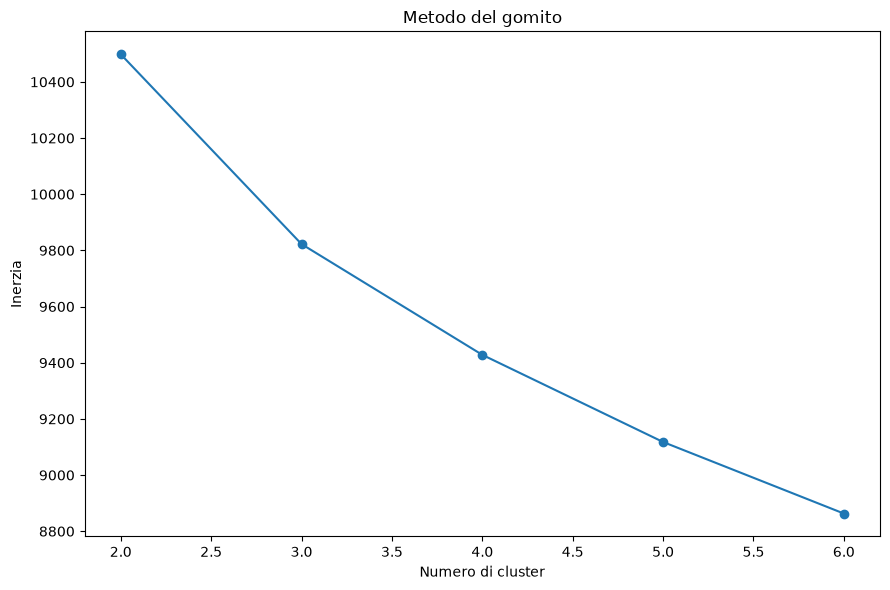

In [12]:
#metodo del gomito
plt.subplots(figsize=(9,6))


plt.plot(cluster_results["k"], cluster_results["inertia"], marker="o")
plt.title("Metodo del gomito")
plt.xlabel("Numero di cluster")
plt.ylabel("Inerzia")

plt.tight_layout()
plt.show()

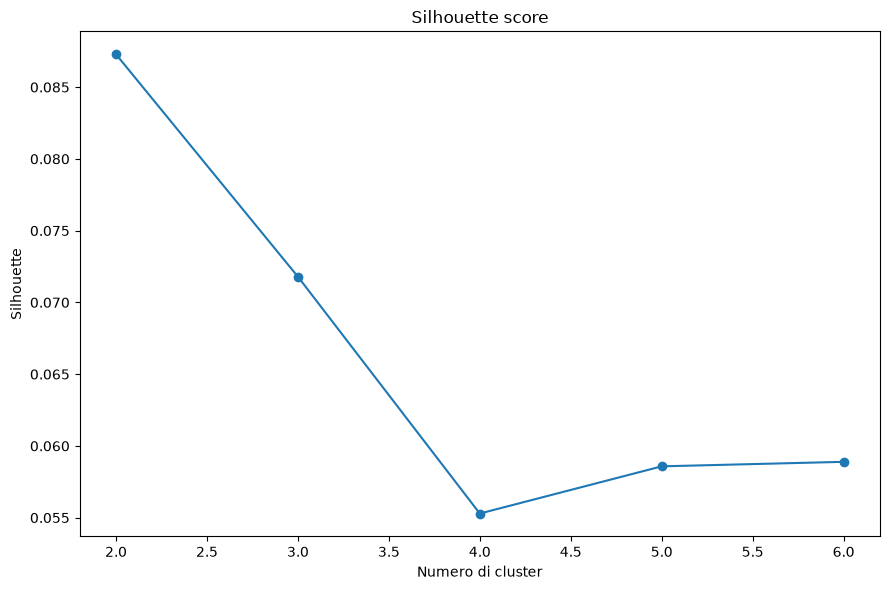

In [13]:
#silhouette score
plt.figure(figsize=(9,6))

plt.plot(cluster_results["k"], cluster_results["silhouette"], marker="o")
plt.title("Silhouette score")
plt.xlabel("Numero di cluster")
plt.ylabel("Silhouette")

plt.tight_layout()
plt.show()

## Scelta del numero di cluster
Il silhouette score massimo è ottenuto per k=2 con un valore pari a **0.0873**, quindi si utilizzeranno 2 cluster.

Il valore assoluto del Silhouette Score rimane comunque basso, indicando una separazione debole tra i profili.



In [14]:
SELECTED_K = 2

In [15]:
kmeans = KMeans(n_clusters=SELECTED_K, n_init=KMEANS_N_INIT, random_state=RANDOM_STATE)
user_features["cluster"] = kmeans.fit_predict(X_users)

print("Dimensione dei cluster:")
display(user_features["cluster"].value_counts().sort_index().to_frame("utenti"))


Dimensione dei cluster:


,utenti
cluster,
0,314
1,296


In [16]:
#preferenze medie per genere 
cluster_preferences = user_features.groupby("cluster")[preference_columns].mean().T
cluster_preferences.index = clustering_genres
display(cluster_preferences.round(3))


cluster,0,1
Action,-0.021,-0.098
Adventure,-0.084,0.048
Animation,-0.069,0.122
Children,-0.143,0.086
Comedy,-0.122,0.005
Crime,0.124,-0.016
Documentary,0.016,0.017
Drama,0.090,0.065
Fantasy,-0.095,0.079
Film-Noir,0.034,0.014


In [17]:
for cluster in cluster_preferences.columns:
    print(f"\nCluster {cluster} - generi più apprezzati:")
    top_genres = (cluster_preferences[cluster].sort_values(ascending=False).head(5).to_frame("preferenza_media"))
    display(top_genres.round(3))

cluster_difference = (cluster_preferences[1] - cluster_preferences[0]).sort_values()



Cluster 0 - generi più apprezzati:


,preferenza_media
Crime,0.124
Drama,0.090
War,0.086
Thriller,0.073
Mystery,0.066



Cluster 1 - generi più apprezzati:


,preferenza_media
Animation,0.122
Children,0.086
Musical,0.086
Fantasy,0.079
War,0.073


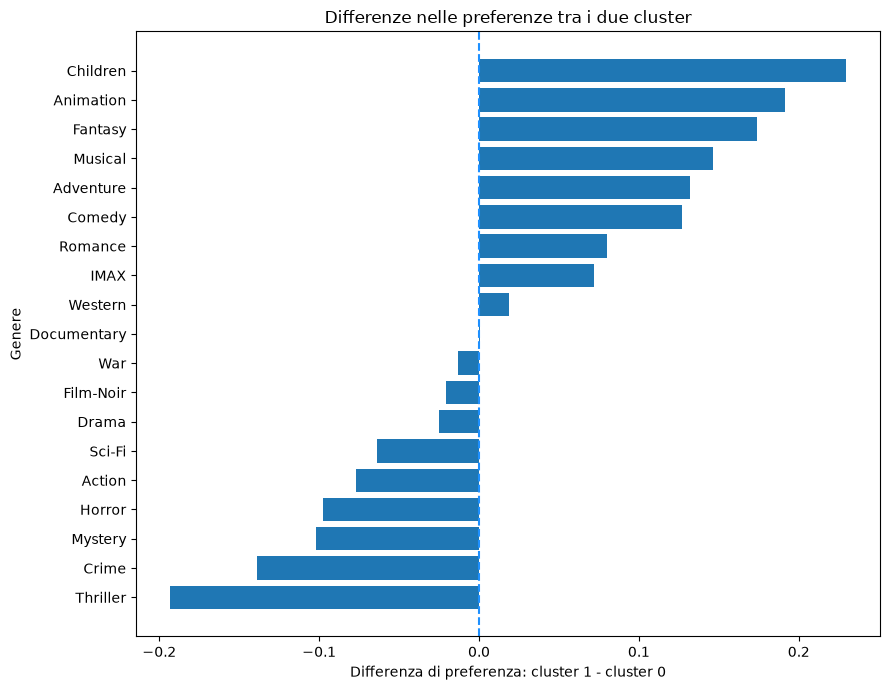

In [18]:
#grafico
plt.figure(figsize=(9,7))

plt.barh(cluster_difference.index, cluster_difference.values)
plt.axvline(0, color="dodgerblue", linestyle="--")

plt.title("Differenze nelle preferenze tra i due cluster")
plt.xlabel("Differenza di preferenza: cluster 1 - cluster 0")
plt.ylabel("Genere")

plt.tight_layout()
plt.show()

### Stabilità del cluster
Oltre alla separazione dei gruppi viene anche verificata la stabilità della soluzione.

Il K-Means viene ripetuto utilizzando diversi valori di *random_state* e ogni nuova partizione viene confrontata con quella di riferimento tramite l'ARI.

Un valore vicino a 1 vuol dire che le due partizioni assegnano gli utenti a gruppi molto simili indipendentemente dal numero di identificazione del cluster.

In [19]:
reference_labels = user_features["cluster"].to_numpy()
stability_scores = []

for seed in range(CLUSTER_STABILITY_RUNS):
    stability_model = KMeans(n_clusters=SELECTED_K, n_init=KMEANS_N_INIT, random_state=seed)

    stability_labels = stability_model.fit_predict(X_users)
    ari = adjusted_rand_score(reference_labels, stability_labels)
    stability_scores.append(ari)

stability_scores = pd.Series(stability_scores, name="Adjusted Rand Index")

print("Stabilità:")
display(stability_scores.describe())

Stabilità:


count    20.000000
mean      0.902095
std       0.059837
min       0.743136
25%       0.914864
50%       0.919583
75%       0.925898
max       0.967428
Name: Adjusted Rand Index, dtype: float64

I risultati completano ciò che è emerso dal Silhouette score, cioè che i gruppi non sono nettamente separati nello spazio ma la struttura individuata da K-Means risulta consistente rispetto all'inizializzazione.

## Interpretazione dei cluster
Il cluster 0 mostra preferenze per generi come Crime, Mystery, Thriller.

Il cluster 1 invece mostra preferenze per Animation, Children, Fantasy e Musical

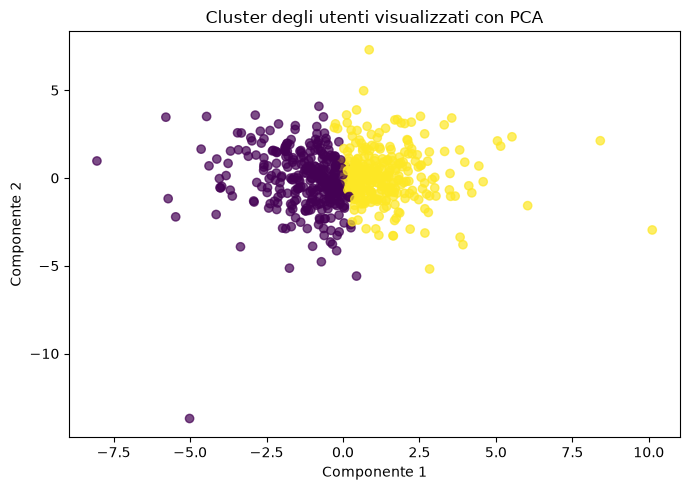

In [20]:
pca = PCA(n_components=PCA_COMPONENTS, random_state=RANDOM_STATE)
points_2d = pca.fit_transform(X_users)

plt.figure(figsize=(7,5))
plt.scatter(points_2d[:, 0], points_2d[:, 1], c=user_features["cluster"], alpha=0.7)

plt.title("Cluster degli utenti visualizzati con PCA")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")

plt.tight_layout()
plt.show()

## Dataset per la previsione e rappresentazione del cluster

Dato che il clustering contiene 2 gruppi l'appartenenza al cluster viene rappresentata tramite una singola variabile binaria: "cluster_1".

Il valore 0 corrisponde al cluster 0;

il valore 1 corrisponde al cluster 1



In [21]:
def prepare_dataset(rating_subset, movie_features_for_stage):
    return(rating_subset.merge(user_features, on="userId", how="left").merge(movie_features_for_stage, on="movieId", how="left"))

train_data = prepare_dataset(train_ratings, movie_data_train)
validation_data = prepare_dataset(validation_ratings, movie_data_validation)

base_features = (["user_mean_rating", 
                  "user_rating_count", 
                  "user_rating_std",
                  "movie_mean_rating", 
                  "movie_rating_count", 
                  "year"]
                + genre_columns)

for name, dataset in {
    "train": train_data, 
    "validation": validation_data
    }.items():
    missing = dataset[base_features].isna().sum().sum()

    print(f"Feature mancanti in {name}: {missing}")


def add_cluster_feature(data):
    X = (data[base_features].copy().reset_index(drop=True))
    X["cluster_1"] = (data["cluster"].reset_index(drop=True).eq(1).astype(int))
    return X
        
X_train_base = train_data[base_features].copy()
X_valid_base = validation_data[base_features].copy()

X_train_cluster = add_cluster_feature(train_data)
X_valid_cluster = add_cluster_feature(validation_data)

y_train = train_data["rating"]
y_valid = validation_data["rating"]

print("\nTraining senza cluster:", X_train_base.shape)
print("Training con cluster:", X_train_cluster.shape)

print("\nValidation senza cluster:", X_valid_base.shape)
print("Validation con cluster:", X_valid_cluster.shape)

Feature mancanti in train: 0
Feature mancanti in validation: 0

Training senza cluster: (19940, 26)
Training con cluster: (19940, 27)

Validation senza cluster: (9818, 26)
Validation con cluster: (9818, 27)


## Baseline e metriche
La baseline più semplice prevede la media globale calcolata su history + train. Viene usata per verificare che i modelli imparino qualcosa di utile.

Poi si usano due metriche per valutare gli errori:

MAE calcola l'errore assoluto medio;

RMSE eleva al quadrato gli scarti prima di calcolarne la media

In [22]:
baseline_predictions = np.full(len(y_valid), global_mean_validation)
baseline_mae, baseline_rmse = evaluate(y_valid, baseline_predictions)

print(f"Baseline - MAE: {baseline_mae:.4f}")
print(f"Baseline - RMSE: {baseline_rmse:.4f}")

Baseline - MAE: 0.8254
Baseline - RMSE: 1.0621


## Random Forest: confronto con e senza cluster

In [23]:
rf_base = RandomForestRegressor(n_estimators=RF_TREES, random_state=RANDOM_STATE, n_jobs=RF_N_JOBS,)
rf_base.fit(X_train_base, y_train)
rf_base_predictions = np.clip(rf_base.predict(X_valid_base), RATING_MIN, RATING_MAX)
rf_base_mae, rf_base_rmse = evaluate(y_valid, rf_base_predictions)
print("Random Forest senza cluster")
print("MAE:", rf_base_mae)
print("RMSE:", rf_base_rmse)

rf_cluster = RandomForestRegressor(n_estimators=RF_TREES, random_state=RANDOM_STATE, n_jobs=RF_N_JOBS,)
rf_cluster.fit(X_train_cluster, y_train)
rf_cluster_predictions = np.clip(rf_cluster.predict(X_valid_cluster), RATING_MIN, RATING_MAX)
rf_cluster_mae, rf_cluster_rmse = evaluate(y_valid, rf_cluster_predictions)
print("\nRandom Forest con cluster")
print("MAE:", rf_cluster_mae)
print("RMSE:", rf_cluster_rmse)

Random Forest senza cluster
MAE: 0.651658887775092
RMSE: 0.8548275319525119

Random Forest con cluster
MAE: 0.6516708984243615
RMSE: 0.8551197434969156


## MLP: confronto con e senza cluster
MLP è sensibile alla scala delle feature quindi viene fatto lo scaling prima

In [24]:
mlp_base = Pipeline([("scaler", StandardScaler()),
                     ("mlp",MLPRegressor(hidden_layer_sizes=MLP_HIDDEN_LAYERS, 
                                         activation=MLP_ACTIVATION, solver=MLP_SOLVER, 
                                         max_iter=MLP_MAX_ITER, early_stopping=MLP_EARLY_STOPPING, 
                                         random_state=RANDOM_STATE))])

mlp_base.fit(X_train_base, y_train)

mlp_base_predictions = np.clip(mlp_base.predict(X_valid_base), RATING_MIN, RATING_MAX)

mlp_base_mae, mlp_base_rmse = evaluate(y_valid, mlp_base_predictions)
print("MLP senza cluster")
print("MAE:", mlp_base_mae)
print("RMSE:", mlp_base_rmse)

mlp_cluster = Pipeline([("scaler", StandardScaler()), 
                        ("mlp",MLPRegressor(hidden_layer_sizes=MLP_HIDDEN_LAYERS,
                                            activation=MLP_ACTIVATION, solver=MLP_SOLVER, 
                                            max_iter=MLP_MAX_ITER, early_stopping=MLP_EARLY_STOPPING, 
                                            random_state=RANDOM_STATE))])
mlp_cluster.fit(X_train_cluster, y_train)

mlp_cluster_predictions = np.clip(mlp_cluster.predict(X_valid_cluster), RATING_MIN, RATING_MAX)

mlp_cluster_mae, mlp_cluster_rmse = evaluate(y_valid, mlp_cluster_predictions)
print("\nMLP con cluster")
print("MAE:", mlp_cluster_mae)
print("RMSE:", mlp_cluster_rmse)

MLP senza cluster
MAE: 0.7080435937934366
RMSE: 0.9218612606457002

MLP con cluster
MAE: 0.7003118649162172
RMSE: 0.9135153130924109


## Confronto sul validation set
Il modello con RMSE più basso viene scelto come modello principale.

In [25]:
validation_results = pd.DataFrame({
    "Modello":["Baseline", "Random Forest senza cluster",
                "Random Forest con cluster", "MLP senza cluster",
                "MLP con cluster",], 
                "MAE": [baseline_mae, rf_base_mae, rf_cluster_mae, mlp_base_mae, mlp_cluster_mae,],
                "RMSE": [baseline_rmse, rf_base_rmse, rf_cluster_rmse, mlp_base_rmse, mlp_cluster_rmse,],
}).sort_values("RMSE")

display(validation_results.round(4))


,Modello,MAE,RMSE
1,Random Forest senza cluster,0.6517,0.8548
2,Random Forest con cluster,0.6517,0.8551
4,MLP con cluster,0.7003,0.9135
3,MLP senza cluster,0.7080,0.9219
0,Baseline,0.8254,1.0621


In [26]:
cluster_effect = pd.DataFrame({
    "modello":["Random Forest", "MLP"],
    "RMSE_senza_cluster": [rf_base_rmse, mlp_base_rmse,],
    "RMSE_con_cluster": [rf_cluster_rmse, mlp_cluster_rmse]
})
cluster_effect["miglioramento_assoluto"] =(cluster_effect["RMSE_senza_cluster"] - cluster_effect["RMSE_con_cluster"])
cluster_effect["miglioramento percentuale"] = (100 * cluster_effect["miglioramento_assoluto"]/cluster_effect["RMSE_senza_cluster"])

display(cluster_effect.round(4))

,modello,RMSE_senza_cluster,RMSE_con_cluster,miglioramento_assoluto,miglioramento percentuale
0,Random Forest,0.8548,0.8551,-0.0003,-0.0342
1,MLP,0.9219,0.9135,0.0083,0.9053


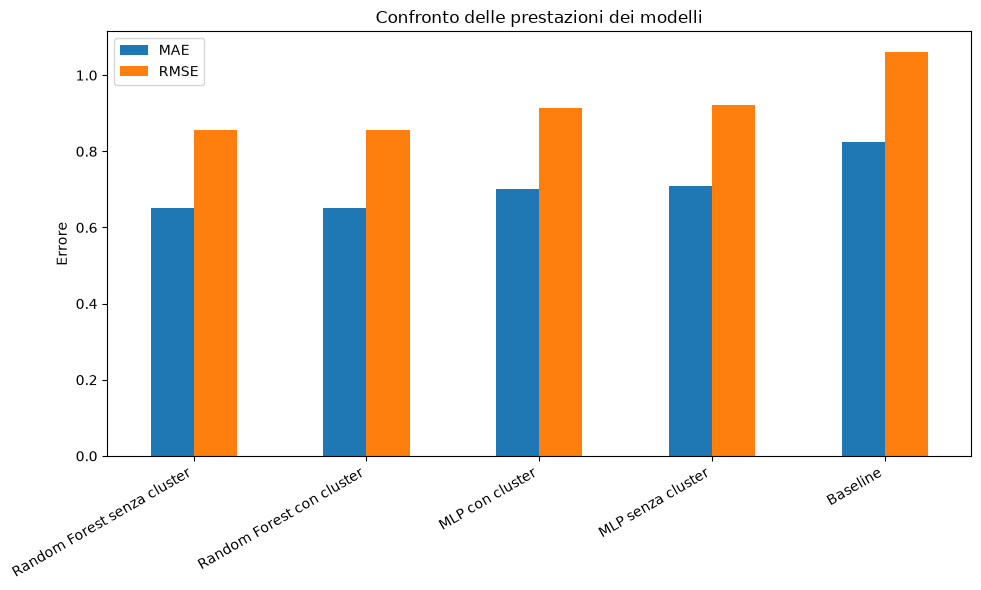

In [27]:
valid_results_plot = validation_results.set_index("Modello")

valid_results_plot[["MAE", "RMSE"]].plot(kind="bar", figsize=(10,6))

plt.title("Confronto delle prestazioni dei modelli")
plt.ylabel("Errore")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Interpretazione del confronto tra modelli
La **Random Forest senza cluster** ottiene l'RMSE più basso

L'aggiunta del cluster produce una variazione minima quindi non determina un miglioramento predittivo notevole.

In MLP invece, aggiungendo il cluster l'RMSE migliora anche se entrambe le configurazioni MLP rimangono meno accurate della Random Forest.

L'effetto dell'informazione di cluster è quindi dipendente dal modello

Il modello selezionato sul validation set quindi è la Random Forest senza cluster.

## Addestramento finale
Dopo aver scelto il modello sul validation set, train e validation vengono uniti per addestrare il modello con più dati.

In [28]:
X_final = pd.concat([X_train_base, X_valid_base], ignore_index=True)
y_final = pd.concat([y_train, y_valid],ignore_index=True)

final_model = (RandomForestRegressor(n_estimators=RF_TREES, random_state=RANDOM_STATE, n_jobs=RF_N_JOBS))
final_model.fit(X_final, y_final)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"

## Test

In [29]:
ratings_known_for_test = pd.concat([history_ratings, train_ratings, validation_ratings], ignore_index=True)
movie_data_test, _, _ = (build_movie_data(ratings_known_for_test))

In [30]:
test_data = prepare_dataset(test_ratings, movie_data_test)

X_test_base = (test_data[base_features].copy())

y_test = test_data["rating"].copy()

In [31]:
test_predictions = np.clip(final_model.predict(X_test_base), RATING_MIN, RATING_MAX)

test_mae, test_rmse = evaluate(y_test, test_predictions)

print(f"Test MAE: {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")

Test MAE: 0.6661
Test RMSE: 0.8676


### Risultato finale sul test set
I risultati ottenuti sono molto vicini a quelli del validation set; 

La vicinanza tra i risultati di validation e test suggerisce che la scelta fatta sul validation set è stabile e che il modello mantiene prestazioni simili su dati non ancora usati.

## Analisi degli errori

,errore assoluto
count,10823.000000
mean,0.666102
std,0.555891
min,0.000000
25%,0.250000
50%,0.537500
75%,0.925000
max,4.365000


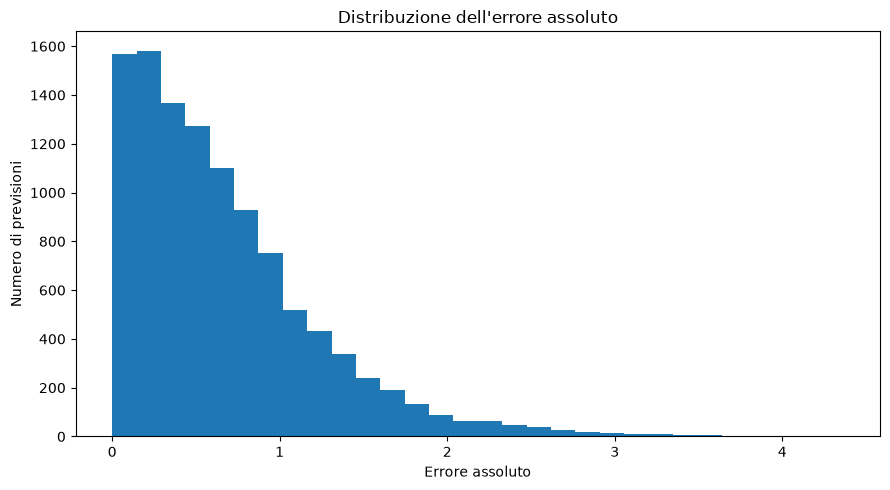

In [32]:
error_analysis = test_data[["userId", "movieId", "title", "rating", "movie_rating_count"]].copy()
error_analysis["predicted_rating"] = test_predictions
error_analysis["absolute_error"] = np.abs(error_analysis["rating"]-error_analysis["predicted_rating"])

display(error_analysis["absolute_error"].describe().to_frame("errore assoluto"))

plt.figure(figsize=(9,5))
plt.hist(error_analysis["absolute_error"], bins=30)
plt.title("Distribuzione dell'errore assoluto")
plt.xlabel("Errore assoluto")
plt.ylabel("Numero di previsioni")
plt.tight_layout()
plt.show()


### Analisi dei film cold start

In [33]:

error_analysis["film_cold_start"] = error_analysis["movie_rating_count"] == 0
display(error_analysis.groupby("film_cold_start")["absolute_error"].agg(["count", "mean"]).rename(columns={"mean": "MAE"}))


,count,MAE
film_cold_start,,
False,9944,0.669424
True,879,0.628519


Non emerge un errore maggiore per i film che non erano mai comparsi nei dati prima del test;

questo però non vuol dire che il problema di cold-start sia risolto: per questi film la media viene sostituita dalla media globale.

Il MAE osservato sui film cold-start risulta in questo specifico test leggermente inferiore rispetto agli altri film. Questo risultato dipende dalla composizione delle osservazioni presenti nel test e non permette di concludere che i film nuovi siano in generale più facili da prevedere.

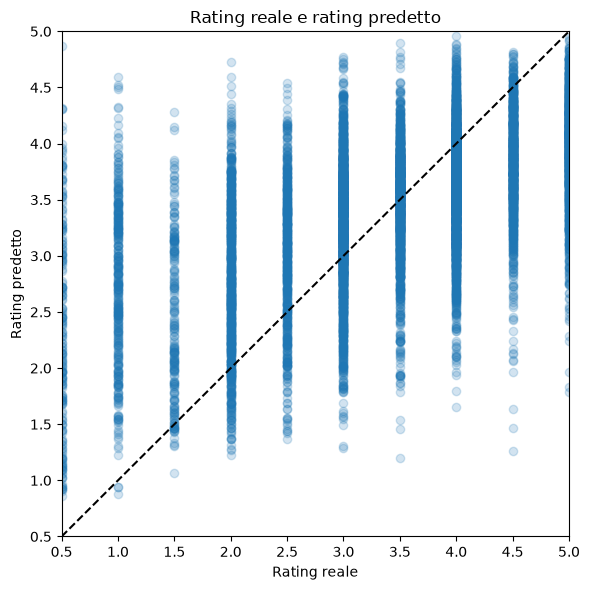

In [34]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, test_predictions, alpha=0.2)
plt.plot([RATING_MIN, RATING_MAX], [RATING_MIN, RATING_MAX], "--", color="black")
plt.xlim(RATING_MIN, RATING_MAX)
plt.ylim(RATING_MIN, RATING_MAX)

plt.title("Rating reale e rating predetto")
plt.xlabel("Rating reale")
plt.ylabel("Rating predetto")
plt.tight_layout()
plt.show()

## Importanza delle feature
La Random Forest permette di visualizzare quali feature sono state usate maggiormente nella costruzione degli alberi. 

,feature,importanza
0,user_mean_rating,0.241757
3,movie_mean_rating,0.220512
5,year,0.107942
4,movie_rating_count,0.101719
2,user_rating_std,0.093290
1,user_rating_count,0.081678
14,Drama,0.014559
11,Comedy,0.014212
7,Action,0.013172
21,Romance,0.012416


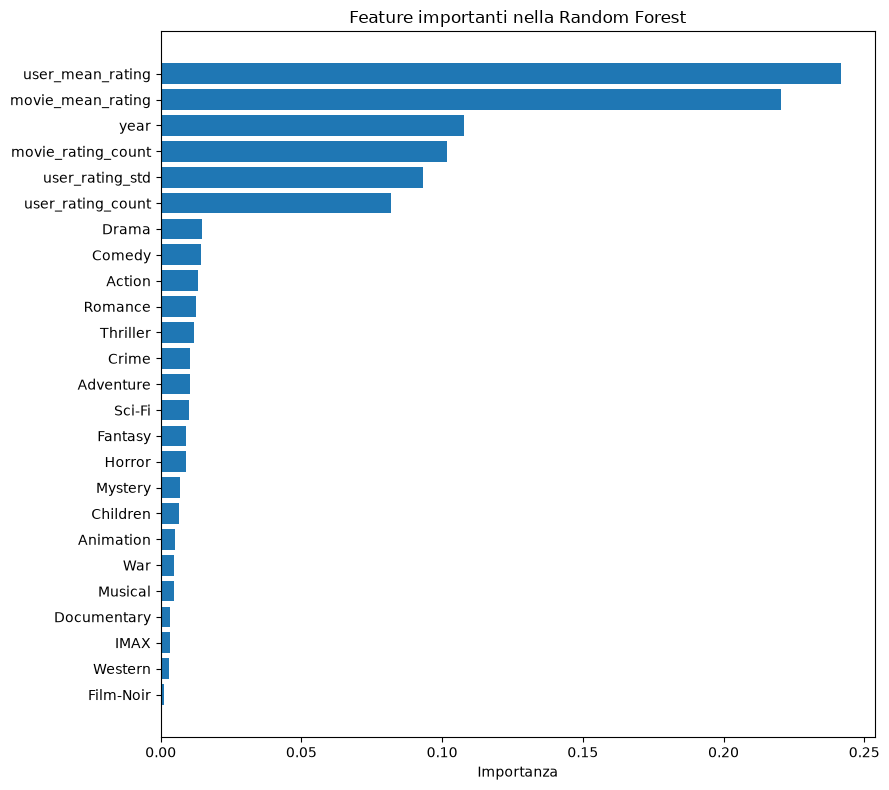

In [35]:
feature_importance = pd.DataFrame({
    "feature": X_final.columns,
    "importanza": final_model.feature_importances_,
}).sort_values("importanza", ascending=False)

display(feature_importance)

plt.figure(figsize=(9,8))
plt.barh(feature_importance["feature"].head(25), feature_importance["importanza"].head(25))
plt.gca().invert_yaxis()

plt.title("Feature importanti nella Random Forest")
plt.xlabel("Importanza")
plt.tight_layout()
plt.show()
